# 09 · District crop model (real data)

Notebook 08 showed the Kaggle-trained model doesn't transfer: real soil never looks like Kaggle's per-crop N-P-K.
Here we train on real data instead.

- **One row per district:** Soil Health Card N, P, K, pH (`data.district_soil()`, kg/ha, the scale on a farmer's card)
  + NASA POWER 2015-2024 weather at the district's market coordinates.
- **Target:** share of the district's area under each crop (DES, each crop's last 5 reported years). Crops grown in
  fewer than 20 districts are dropped. Trained as a multiclass model with one row per district × crop, weighted by the
  area share, so the predicted probability is *the share of farmland that similar places put under each crop*.
- **Validation: leave one state out.** Neighbouring districts share soil, weather and crops, so random folds would
  flatter the model. Every district is scored by a model that never saw its state.
- **Metrics per district:** main crop 1st; main crop in the list; share of list crops the district grows;
  share of the district's area covered by the list. List = top 3 with probability ≥ 5% (as in the app).
- **Baseline:** popularity, the 3 crops with most area in the training states (refit each fold, so it's fair now).

Suitability now means "what farmers in similar soil and climate grow", not "what grows best agronomically":
revealed preference, which bakes in irrigation, markets and habit. The paper must say so.

In [1]:
import sys
sys.path.insert(0, '../project')
import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import data
import recommend

SEED = 42
MIN_DISTRICTS = 20
RESULTS, FIGS = Path('../research/results'), Path('../research/figures')
pd.set_option('display.width', 220)

## 1. Training table

In [2]:
soil = data.district_soil().dropna()
soil = soil[soil.samples >= 100]
area = data.district_yield()[['crop', 'district_code', 'area_ha']]
keep = area.crop.value_counts().loc[lambda s: s >= MIN_DISTRICTS].index
area = area[area.crop.isin(keep)]
d = recommend._tables()[2].merge(soil, on='district_code')
d = d[d.district_code.isin(area.district_code)].reset_index(drop=True)


d = pd.concat([d, pd.DataFrame([recommend.weather(r.lat, r.lon) for r in d.itertuples()])], axis=1)  # same code as the app
shares = area.pivot_table(index='district_code', columns='crop', values='area_ha', fill_value=0).loc[d.district_code]
shares = shares.div(shares.sum(axis=1), axis=0)
classes = list(shares.columns)
S = shares.values
main_idx = S.argmax(axis=1)
states = d.state_name.values
print(f'{len(d)} districts, {d.state_name.nunique()} states, {len(classes)} crops: {", ".join(classes)}')
pd.DataFrame({'main crop in % of districts': pd.Series(np.array(classes)[main_idx]).value_counts(normalize=True) * 100,
              '% of all area': shares.mul(d.set_index('district_code').index.map(area.groupby('district_code').area_ha.sum()), axis=0).sum() / area.area_ha.sum() * 100}).fillna(0).round(1).sort_values('% of all area', ascending=False)

539 districts, 28 states, 16 crops: banana, blackgram, chickpea, coconut, cotton, grapes, jute, lentil, maize, mango, mothbeans, mungbean, orange, papaya, pigeonpeas, rice


,main crop in % of districts,% of all area
rice,69.0,39.7
cotton,9.3,10.8
maize,8.5,8.3
chickpea,6.3,7.4
pigeonpeas,0.7,4.3
blackgram,1.9,3.9
mungbean,0.4,2.5
lentil,0.0,1.7
coconut,2.8,1.3
mango,0.7,0.7


## 2. Leave-state-out comparison

In [3]:
FEATURES = {
    'soil + weather (app inputs)': ['N', 'P', 'K', 'ph', 'temperature', 'rainfall'],
    '+ humidity': ['N', 'P', 'K', 'ph', 'temperature', 'humidity', 'rainfall'],
    '+ season weather': ['N', 'P', 'K', 'ph', 'temperature', 'humidity', 'rainfall', 'rain_kharif', 'rain_rabi', 'temp_kharif', 'temp_rabi'],
    'weather only': ['temperature', 'humidity', 'rainfall'],
    'soil only': ['N', 'P', 'K', 'ph'],
}
MODELS = {
    'Random Forest': lambda: RandomForestClassifier(n_estimators=500, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
    'LightGBM': lambda: LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=10,
                                       random_state=SEED, verbose=-1),
    'Logistic regression': lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)),
}


def long_rows(idx, feats):
    """One row per district x crop with area share > 0, weighted by the share."""
    i, c = np.nonzero(S[idx] > 0)
    return d.loc[idx[i], feats].reset_index(drop=True), c, S[idx][i, c]


def fit(model, X, y, w):
    key = f'{model.steps[-1][0]}__sample_weight' if hasattr(model, 'steps') else 'sample_weight'  # pipelines route by step name
    return model.fit(X, y, **{key: w})


def full_proba(model, X):
    P = np.zeros((len(X), len(classes)))
    P[:, model.classes_] = model.predict_proba(X)  # a fold may miss a rare crop
    return P


def score(P, idx):
    order = np.argsort(-P, axis=1)[:, :3]
    keep = np.take_along_axis(P, order, axis=1) >= recommend.MIN_SUITABILITY
    keep[:, 0] = True
    s, main = S[idx], main_idx[idx]
    picked = [o[k] for o, k in zip(order, keep)]
    return {'main crop 1st %': np.mean(order[:, 0] == main) * 100,
            'main crop in list %': np.mean([m in p for m, p in zip(main, picked)]) * 100,
            'picks grown %': np.mean([np.mean(r[p] > 0) for r, p in zip(s, picked)]) * 100,
            'area covered %': np.mean([r[p].sum() for r, p in zip(s, picked)]) * 100,
            'list length': np.mean([len(p) for p in picked])}


def cv_proba(make, feats, splitter):
    P = np.zeros_like(S)
    for tr, te in splitter.split(d, groups=states):
        X, y, w = long_rows(tr, feats)
        P[te] = full_proba(fit(make(), X, y, w), d.loc[te, feats])
    return P


def popularity_proba(splitter):
    P = np.zeros_like(S)
    for tr, te in splitter.split(d, groups=states):
        P[te] = S[tr].mean(axis=0)
    return P


logo = LeaveOneGroupOut()
all_idx = np.arange(len(d))
rows = {'popularity (training states)': score(popularity_proba(logo), all_idx)}
oof = {}
for mname, make in MODELS.items():
    for fname, feats in FEATURES.items():
        oof[mname, fname] = cv_proba(make, feats, logo)
        rows[f'{mname} · {fname}'] = score(oof[mname, fname], all_idx)
cv = pd.DataFrame(rows).T
cv.round(1)

,main crop 1st %,main crop in list %,picks grown %,area covered %,list length
popularity (training states),69.0,82.6,89.4,71.5,3.0
Random Forest · soil + weather (app inputs),67.3,85.9,93.5,74.0,2.8
Random Forest · + humidity,67.3,87.0,94.3,75.3,2.7
Random Forest · + season weather,68.3,89.8,96.6,77.5,2.7
Random Forest · weather only,60.1,82.9,93.4,72.8,2.7
Random Forest · soil only,67.3,83.3,91.2,71.9,2.8
LightGBM · soil + weather (app inputs),62.5,83.7,96.7,70.8,2.3
LightGBM · + humidity,62.3,82.6,96.0,70.3,2.3
LightGBM · + season weather,65.9,85.7,98.9,72.8,2.2
LightGBM · weather only,57.1,78.5,96.1,68.2,2.4


In [4]:
# Random 5-fold over districts (not grouped by state): how much would ignoring geography flatter the model?
best_feats = FEATURES['soil + weather (app inputs)']
rand = np.zeros_like(S)
for tr, te in KFold(5, shuffle=True, random_state=SEED).split(d):
    X, y, w = long_rows(tr, best_feats)
    rand[te] = full_proba(fit(MODELS['Random Forest'](), X, y, w), d.loc[te, best_feats])
cv.loc['Random Forest · app inputs, random district folds'] = score(rand, all_idx)
cv.round(2).rename_axis('model · features').to_csv(RESULTS / '2026-11-04_district_model_cv.csv')
cv.loc[['popularity (training states)', 'Random Forest · soil + weather (app inputs)',
        'Random Forest · app inputs, random district folds']].round(1)

,main crop 1st %,main crop in list %,picks grown %,area covered %,list length
popularity (training states),69.0,82.6,89.4,71.5,3.0
Random Forest · soil + weather (app inputs),67.3,85.9,93.5,74.0,2.8
"Random Forest · app inputs, random district folds",73.5,90.9,96.9,79.4,2.6


In [5]:
# Paired bootstrap over districts: is the gain over popularity, and from season weather, real?
rng = np.random.default_rng(SEED)


def per_district(P):
    order = np.argsort(-P, axis=1)[:, :3]
    ok = np.take_along_axis(P, order, axis=1) >= recommend.MIN_SUITABILITY
    ok[:, 0] = True
    return np.array([m in o[k] for m, o, k in zip(main_idx, order, ok)], float)


hits = {'popularity': per_district(popularity_proba(logo)),
        'RF app inputs': per_district(oof['Random Forest', 'soil + weather (app inputs)']),
        'RF + season weather': per_district(oof['Random Forest', '+ season weather']),
        'LogReg + season weather': per_district(oof['Logistic regression', '+ season weather'])}
boot = rng.integers(0, len(d), (2000, len(d)))
pairs = [('RF app inputs', 'popularity'), ('RF + season weather', 'popularity'), ('RF + season weather', 'RF app inputs'),
         ('LogReg + season weather', 'RF + season weather')]
pd.DataFrame([{'comparison': f'{a} vs {b}', 'diff, main crop in top 3 (pts)': (hits[a] - hits[b]).mean() * 100,
               '95% CI low': np.percentile((hits[a] - hits[b])[boot].mean(1), 2.5) * 100,
               '95% CI high': np.percentile((hits[a] - hits[b])[boot].mean(1), 97.5) * 100} for a, b in pairs]).round(1)

,comparison,"diff, main crop in top 3 (pts)",95% CI low,95% CI high
0,RF app inputs vs popularity,3.3,0.4,6.5
1,RF + season weather vs popularity,7.2,3.9,10.4
2,RF + season weather vs RF app inputs,3.9,1.1,6.5
3,LogReg + season weather vs RF + season weather,-1.9,-4.5,1.1


Kaggle model on the same question (notebook 08, SHC raw soil): main crop 1st 6.3%, in list 7.8%;
random 3 crops: 5.0% / 16.0%.

In [6]:
# Per-state view for the app model choice: where does it beat popularity, where not?
P_app, P_pop = oof['Random Forest', 'soil + weather (app inputs)'], popularity_proba(logo)
per_state = pd.DataFrame({
    'districts': pd.Series(states).value_counts(),
    'RF main in list %': pd.Series({s: score(P_app[states == s], all_idx[states == s])['main crop in list %'] for s in set(states)}),
    'popularity main in list %': pd.Series({s: score(P_pop[states == s], all_idx[states == s])['main crop in list %'] for s in set(states)}),
    'RF area covered %': pd.Series({s: score(P_app[states == s], all_idx[states == s])['area covered %'] for s in set(states)}),
})
per_state.sort_values('districts', ascending=False).round(0).head(20)

,districts,RF main in list %,popularity main in list %,RF area covered %
Uttar Pradesh,75,89.0,91.0,73.0
Madhya Pradesh,52,67.0,56.0,54.0
Bihar,37,92.0,100.0,77.0
Tamil Nadu,36,67.0,72.0,54.0
Maharashtra,34,82.0,85.0,67.0
Gujarat,32,88.0,41.0,70.0
Telangana,32,84.0,78.0,77.0
Karnataka,31,65.0,61.0,54.0
Odisha,30,100.0,100.0,88.0
Chhattisgarh,27,100.0,100.0,95.0


## 3. App model

In [7]:
APP_FEATURES = FEATURES['+ season weather']  # the card's N, P, K, pH + everything recommend.weather() returns
X, y, w = long_rows(all_idx, APP_FEATURES)
forest = fit(MODELS['Random Forest'](), X, y, w)
joblib.dump({'model': forest, 'forest': forest, 'features': APP_FEATURES, 'classes': [classes[i] for i in forest.classes_]},
            Path('../models/crop_model.joblib'))
print('saved ../models/crop_model.joblib:', len(forest.classes_), 'crops')

saved ../models/crop_model.joblib: 16 crops


In [8]:
# Sanity check through the app: five districts with their own SHC soil
recommend._model.cache_clear(); recommend._explainer.cache_clear()
SOW = datetime.date(2026, 11, 4)
ex = []
for name in ['Raipur', 'Yavatmal', 'Vidisha', 'Nashik', 'Ludhiana', 'Thanjavur']:
    if name not in d.district_name.values:
        print(name, 'skipped: fewer than 100 SHC tests or no DES area')
        continue
    r = d[d.district_name == name].iloc[0]
    _, t = recommend.recommend(r.N, r.P, r.K, r.ph, name, r.state_name, sow=SOW)
    ex.append(t.assign(district=name, N=r.N, P=r.P, K=r.K, ph=r.ph, rank=t.index,
                       actual_top3=' > '.join(shares.loc[r.district_code].nlargest(3).index)))
ex = pd.concat(ex, ignore_index=True)
ex.to_csv(RESULTS / '2026-11-04_district_model_examples.csv', index=False)
ex[['district', 'rank', 'crop', 'suitability', 'near_tie', 'net_rs_ha', 'actual_top3']]

Ludhiana skipped: fewer than 100 SHC tests or no DES area


,district,rank,crop,suitability,near_tie,net_rs_ha,actual_top3
0,Raipur,1,rice,0.966,True,28269.0,rice > chickpea > lentil
1,Yavatmal,1,cotton,0.621,True,7335.0,cotton > pigeonpeas > chickpea
2,Yavatmal,2,pigeonpeas,0.171,False,19288.0,cotton > pigeonpeas > chickpea
3,Yavatmal,3,chickpea,0.157,False,18727.0,cotton > pigeonpeas > chickpea
4,Vidisha,1,chickpea,0.380,True,42636.0,chickpea > blackgram > lentil
5,Vidisha,2,blackgram,0.318,True,5046.0,chickpea > blackgram > lentil
6,Vidisha,3,lentil,0.149,False,32009.0,chickpea > blackgram > lentil
7,Nashik,1,maize,0.438,True,22885.0,maize > rice > cotton
8,Nashik,2,rice,0.187,False,-22390.0,maize > rice > cotton
9,Nashik,3,cotton,0.132,False,9170.0,maize > rice > cotton


ph             0.057
N              0.060
P              0.063
rain_kharif    0.074
K              0.078
temperature    0.078
temp_kharif    0.101
rainfall       0.107
humidity       0.111
rain_rabi      0.133
temp_rabi      0.138
dtype: float64

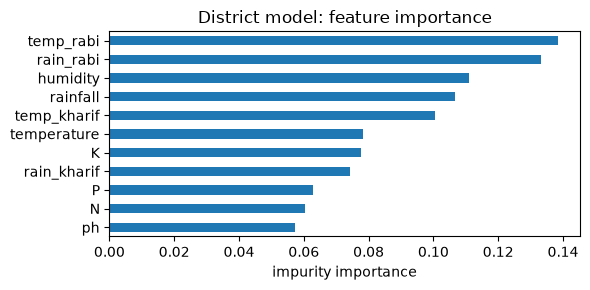

In [9]:
imp = pd.Series(forest.feature_importances_, index=APP_FEATURES).sort_values()
ax = imp.plot.barh(figsize=(6, 3)); ax.set_xlabel('impurity importance'); ax.set_title('District model: feature importance')
plt.tight_layout(); plt.savefig(FIGS / 'district_model_importance.png', dpi=150)
imp.round(3)

## 4. Findings

1. **Real data fixes the transfer problem.** Leave-one-state-out, the district model puts the main crop in its list for
   86% of districts (90% with season weather); the Kaggle model managed 8% on the same districts (notebook 08).
2. **But the bar is low.** Rice is the main crop in 69% of districts among these 16 crops, so "the 3 most common crops"
   already scores 83%. The app model beats that by 7.2 points (95% CI 3.9–10.4, paired bootstrap), but it is no better
   at putting the main crop *first* (68% vs 69%).
   It earns its keep in mixed-crop states (Gujarat, Madhya Pradesh); in rice states everything is right.
3. **Season weather helps every model** (RF +3.9 pts main crop in list, CI 1.1–6.5; +3.5 pts area covered). The app now uses it.
4. Random Forest and logistic regression are level (difference −1.9 pts, CI −4.5 to 1.1); LightGBM is the weakest. RF stays
   for the app because the SHAP explainer and the agent's tools are built on it.
5. Random district folds would report 90.9% instead of 85.9% for the same model: geography leaks between neighbours.
   The five example districts match their real top 3 almost exactly, but they were in training, so that is no evidence.
6. **Biggest limit:** wheat, sugarcane, soybean, groundnut, mustard and bajra are not in the Kaggle crop list, so the
   app can't recommend them and "main crop" here is the main crop *among these 16*. Adding them needs prices
   (notebook 06), DES names and CACP costs for each.
7. Suitability is revealed preference (what similar districts grow), not agronomic fit, and it is trained on district
   averages while the app gets one farm's card.